# NutriPath — Notebook 2: Modeling
**Input:** nutripath_gold (Delta table from NB1)  
**Output:** Trained XGBoost model saved in MLflow  
**Goal:** Train a model that predicts A1C reduction from a patient profile,
so the chatbot can generate personalized meal, activity, and sleep plans.

## Notebook structure
- **Stage 1** — Load Gold and prepare data for modeling
- **Stage 2** — Train XGBoost and track with MLflow
- **Stage 3** — Evaluate on held-out test set
- **Stage 4** — Feature importance and model interpretation
- **Stage 5** — Save model for Streamlit deployment

## 📥 Stage 1 — Data Preparation
Read from nutripath_gold, define features and target,
split into train / validation / test sets.

In [0]:
# Load Gold data
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

# Load Gold table — this is the model-ready data from NB1
gold_pd = spark.read.table(
    "`chieac-healthcare-chatbot-project`.default.nutripath_gold"
).toPandas()

print(f"✓ Gold loaded: {gold_pd.shape[0]:,} rows × {gold_pd.shape[1]} columns")
print(f"  Target variable: predicted_a1c_reduction_3mo")
print(f"  Target mean:     {gold_pd['predicted_a1c_reduction_3mo'].mean():.3f}%")
print(f"  Target range:    {gold_pd['predicted_a1c_reduction_3mo'].min():.3f}% "
      f"to {gold_pd['predicted_a1c_reduction_3mo'].max():.3f}%")

✓ Gold loaded: 100,000 rows × 59 columns
  Target variable: predicted_a1c_reduction_3mo
  Target mean:     0.434%
  Target range:    0.000% to 2.846%


In [0]:
# Define features and target column

# These are the 41 input features the model learns from
# predicted_a1c_reduction_3mo is the target (what we're predicting)
feature_columns = [
    # Clinical
    "age", "bmi", "a1c_percent", "diabetes_duration_yrs",
    "fasting_glucose_mgdl", "systolic_bp", "diastolic_bp",
    "egfr", "ldl_mgdl", "hdl_mgdl", "triglycerides_mgdl",
    "sleep_hours_per_night", "caloric_intake_kcal",
    "carb_intake_grams", "meals_per_day",
    "fruit_veg_servings_per_day",
    "dietary_adherence_score_1to10",

    # Encoded categoricals
    "activity_level_encoded", "glycemic_control_encoded",
    "sleep_quality_encoded", "motivation_encoded",
    "sex_encoded", "gi_awareness_encoded", "ckd_stage_encoded",

    # Medications
    "on_metformin", "on_glp1_agonist", "on_insulin",
    "on_sglt2_inhibitor", "on_statin",

    # Comorbidities
    "hypertension", "dyslipidemia", "obesity",
    "peripheral_neuropathy", "retinopathy",

    # Engineered features
    "motivation_score", "dietary_pattern_score",
    "medication_count", "comorbidity_count",
    "high_risk_flag", "carb_load_ratio", "sleep_deprived",
]

target_column = "predicted_a1c_reduction_3mo"

X = gold_pd[feature_columns]
y = gold_pd[target_column]

print(f"✓ Features: {len(feature_columns)}")
print(f"✓ Target:   {target_column}")
print(f"\nFeature matrix shape: {X.shape}")
print(f"Target vector shape:  {y.shape}")

✓ Features: 41
✓ Target:   predicted_a1c_reduction_3mo

Feature matrix shape: (100000, 41)
Target vector shape:  (100000,)


In [0]:
# Train/test/validation data split

from sklearn.model_selection import train_test_split

# Step 1: split off test set (15%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42
)

# Step 2: split remaining into train (70%) and validation (15%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.1765, random_state=42
    # 0.1765 of 85% ≈ 15% of total
)

print(f"✓ Data split complete:")
print(f"  Training:   {len(X_train):>7,} rows ({len(X_train)/len(X)*100:.0f}%)")
print(f"  Validation: {len(X_val):>7,} rows ({len(X_val)/len(X)*100:.0f}%)")
print(f"  Test:       {len(X_test):>7,} rows ({len(X_test)/len(X)*100:.0f}%)")
print(f"\n  ⚠️  Test set is held out — not touched until final evaluation")

✓ Data split complete:
  Training:    69,997 rows (70%)
  Validation:  15,003 rows (15%)
  Test:        15,000 rows (15%)

  ⚠️  Test set is held out — not touched until final evaluation


In [0]:
# Confirm no nulls exist in features — XGBoost will fail silently on nulls
null_check = X_train.isnull().sum()
nulls_found = null_check[null_check > 0]

if len(nulls_found) == 0:
    print("✓ Zero nulls in training features — safe to proceed")
else:
    print(f"⚠️ Nulls found in {len(nulls_found)} columns:")
    print(nulls_found)
    print("Fix these before training")

✓ Zero nulls in training features — safe to proceed


## 🤖 Stage 2 — Model Training
Train XGBoost with MLflow experiment tracking.
Every run is automatically logged — parameters, metrics, and the model itself.

In [0]:
# Set up MLflow experiment

import mlflow
import mlflow.xgboost
from databricks.sdk import WorkspaceClient

# Create the parent workspace directory so MLflow can place the experiment here
WorkspaceClient().workspace.mkdirs("/NutriPath")

# All runs will be grouped here — visible in the MLflow UI
mlflow.set_experiment("/NutriPath/a1c_reduction_model")

print("✓ MLflow experiment set: /NutriPath/a1c_reduction_model")
print("  Find it in Databricks: Experiments → NutriPath")

✓ MLflow experiment set: /NutriPath/a1c_reduction_model
  Find it in Databricks: Experiments → NutriPath


In [0]:
# Installing xg boost
%pip install xgboost

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
# Train baseline model

from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# XGBoost requires numeric dtypes — convert any object columns
object_cols = X_train.select_dtypes(include='object').columns
for _df in [X_train, X_val, X_test]:
    for _col in object_cols:
        _df[_col] = pd.to_numeric(_df[_col], errors='coerce')

def evaluate(model, X, y, label=""):
    """Helper — returns RMSE, MAE, R² for any split"""
    preds = model.predict(X)
    rmse = np.sqrt(mean_squared_error(y, preds))
    mae  = mean_absolute_error(y, preds)
    r2   = r2_score(y, preds)
    if label:
        print(f"  {label:<12} RMSE: {rmse:.4f}  MAE: {mae:.4f}  R²: {r2:.4f}")
    return rmse, mae, r2

# Run 1 — Baseline with default parameters
with mlflow.start_run(run_name="baseline"):

    params = {
        "n_estimators":     300,
        "max_depth":        6,
        "learning_rate":    0.1,
        "subsample":        0.8,
        "colsample_bytree": 0.8,
        "random_state":     42,
        "n_jobs":           -1,
    }

    model_baseline = XGBRegressor(**params)
    model_baseline.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    # Evaluate on all three splits
    print("Baseline model performance:")
    train_rmse, train_mae, train_r2 = evaluate(
        model_baseline, X_train, y_train, "Train"
    )
    val_rmse, val_mae, val_r2 = evaluate(
        model_baseline, X_val, y_val, "Validation"
    )

    # Log everything to MLflow
    mlflow.log_params(params)
    mlflow.log_metrics({
        "train_rmse": train_rmse, "train_mae": train_mae, "train_r2": train_r2,
        "val_rmse":   val_rmse,   "val_mae":   val_mae,   "val_r2":   val_r2,
    })
    mlflow.xgboost.log_model(model_baseline, "model")

    print(f"\n✓ Baseline run logged to MLflow")

Baseline model performance:
  Train        RMSE: 0.0923  MAE: 0.0702  R²: 0.9336


2026/09/04 21:44:43 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


  Validation   RMSE: 0.1066  MAE: 0.0806  R²: 0.9083


🔗 View Logged Model at: https://dbc-1c9f9e50-73c5.cloud.databricks.com/ml/experiments/3450930886620028/models/m-587e34b10af24738a52d6bfd19de5bf3?o=7474646839730868
2026/09/04 21:44:49 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.8.1/ml/model/signatures.html for instructions on setting signature on models.



✓ Baseline run logged to MLflow


In [0]:
# Train improved model

# Run 2 — Tuned parameters for better generalization
with mlflow.start_run(run_name="tuned"):

    params_tuned = {
        "n_estimators":     500,
        "max_depth":        5,
        "learning_rate":    0.05,
        "subsample":        0.75,
        "colsample_bytree": 0.75,
        "min_child_weight": 3,
        "gamma":            0.1,
        "reg_alpha":        0.1,
        "reg_lambda":       1.5,
        "random_state":     42,
        "n_jobs":           -1,
    }

    model_tuned = XGBRegressor(**params_tuned)
    model_tuned.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    print("Tuned model performance:")
    train_rmse, train_mae, train_r2 = evaluate(
        model_tuned, X_train, y_train, "Train"
    )
    val_rmse, val_mae, val_r2 = evaluate(
        model_tuned, X_val, y_val, "Validation"
    )

    mlflow.log_params(params_tuned)
    mlflow.log_metrics({
        "train_rmse": train_rmse, "train_mae": train_mae, "train_r2": train_r2,
        "val_rmse":   val_rmse,   "val_mae":   val_mae,   "val_r2":   val_r2,
    })
    mlflow.xgboost.log_model(model_tuned, "model")

    print(f"\n✓ Tuned run logged to MLflow")

Tuned model performance:
  Train        RMSE: 0.1040  MAE: 0.0789  R²: 0.9156
  Validation   RMSE: 0.1058  MAE: 0.0800  R²: 0.9096


2026/09/04 21:45:21 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
🔗 View Logged Model at: https://dbc-1c9f9e50-73c5.cloud.databricks.com/ml/experiments/3450930886620028/models/m-b7fd09df9bdd4cfc8f46b00f95c5ffc5?o=7474646839730868
2026/09/04 21:45:24 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.8.1/ml/model/signatures.html for instructions on setting signature on models.



✓ Tuned run logged to MLflow


## 📊 Stage 3 — Evaluation on held-out test set
The test set has never been seen by the model.
These numbers are the honest, unbiased performance estimate —
the ones you report to the exec director and put on your resume.

In [0]:
# Use the tuned model for final evaluation
# Test set is touched only once — right here
test_preds = model_tuned.predict(X_test)

test_rmse = np.sqrt(mean_squared_error(y_test, test_preds))
test_mae  = mean_absolute_error(y_test, test_preds)
test_r2   = r2_score(y_test, test_preds)

print("=" * 50)
print("FINAL TEST SET PERFORMANCE")
print("=" * 50)
print(f"  RMSE: {test_rmse:.4f}%")
print(f"  MAE:  {test_mae:.4f}%")
print(f"  R²:   {test_r2:.4f}")
print("=" * 50)
print(f"\nInterpretation:")
print(f"  On average the model's prediction is off by {test_mae:.3f}%")
print(f"  The model explains {test_r2*100:.1f}% of variation in A1C reduction")

FINAL TEST SET PERFORMANCE
  RMSE: 0.1055%
  MAE:  0.0801%
  R²:   0.9102

Interpretation:
  On average the model's prediction is off by 0.080%
  The model explains 91.0% of variation in A1C reduction


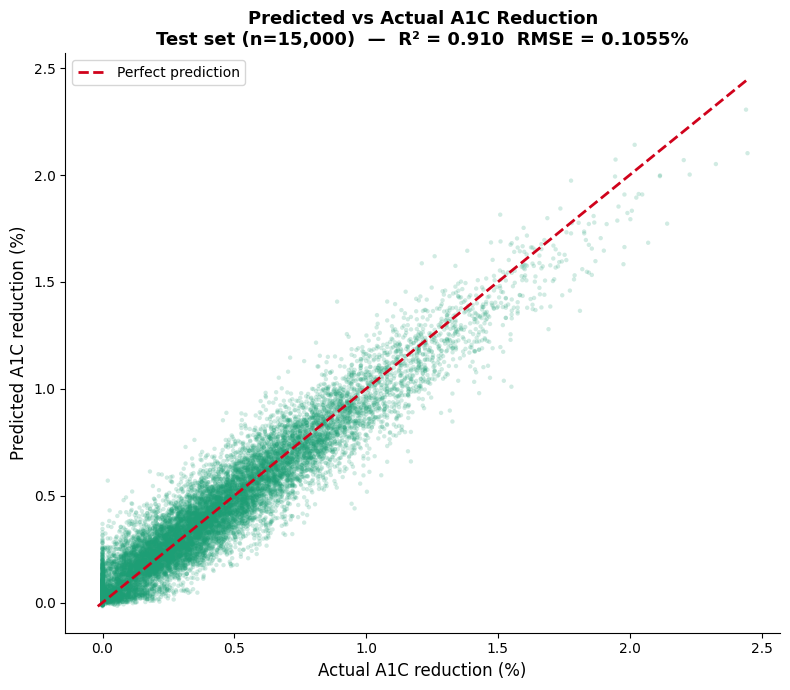

In [0]:
# Plot predicted vs actual ALC reduction % chart 

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 7))

ax.scatter(
    y_test, test_preds,
    alpha=0.2, s=10,
    color="#1D9E75", edgecolors="none"
)

# Perfect prediction line
min_val = min(y_test.min(), test_preds.min())
max_val = max(y_test.max(), test_preds.max())
ax.plot([min_val, max_val], [min_val, max_val],
        color="#D0021B", linewidth=2,
        linestyle="--", label="Perfect prediction")

ax.set_xlabel("Actual A1C reduction (%)", fontsize=12)
ax.set_ylabel("Predicted A1C reduction (%)", fontsize=12)
ax.set_title(f"Predicted vs Actual A1C Reduction\n"
             f"Test set (n={len(y_test):,})  —  "
             f"R² = {test_r2:.3f}  RMSE = {test_rmse:.4f}%",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

## 🔍 Stage 4 — Feature Importance
Which features drive A1C reduction predictions most?
This directly informs what the chatbot prioritizes in its plans.
High-importance features = the chatbot addresses these first.

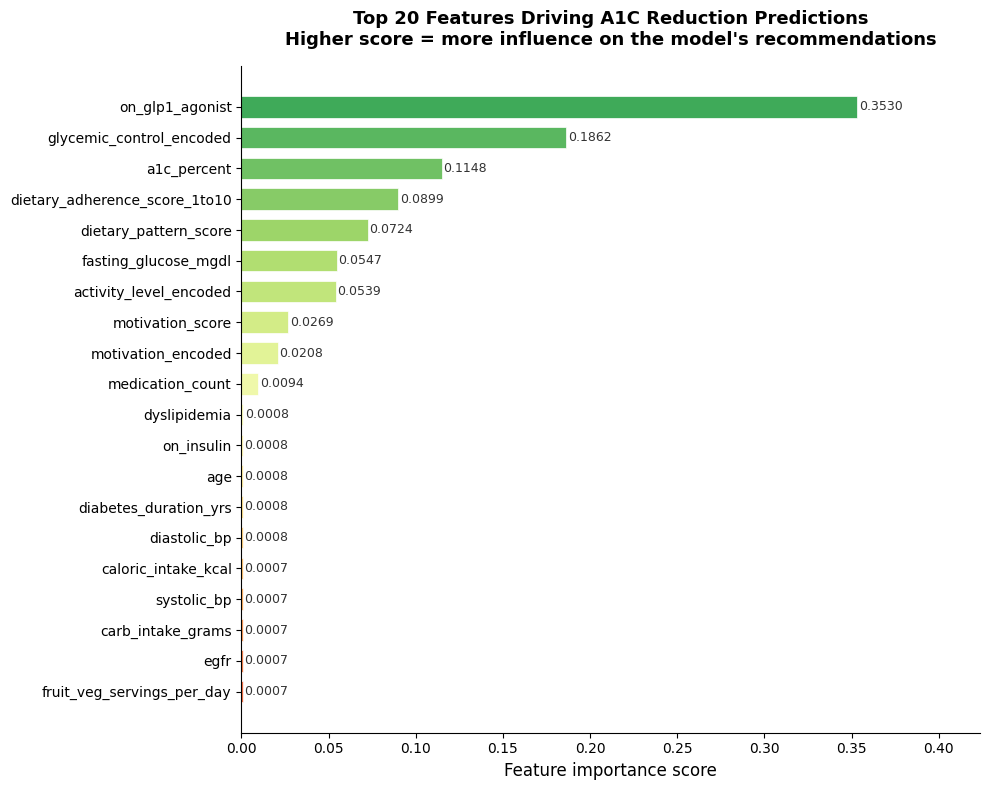


Top 10 most important features:
   1. on_glp1_agonist                          0.3530
   2. glycemic_control_encoded                 0.1862
   3. a1c_percent                              0.1148
   4. dietary_adherence_score_1to10            0.0899
   5. dietary_pattern_score                    0.0724
   6. fasting_glucose_mgdl                     0.0547
   7. activity_level_encoded                   0.0539
   8. motivation_score                         0.0269
   9. motivation_encoded                       0.0208
  10. medication_count                         0.0094


In [0]:
# Get feature importance scores from the tuned model
importance_df = pd.DataFrame({
    "feature":    feature_columns,
    "importance": model_tuned.feature_importances_
}).sort_values("importance", ascending=True).tail(20)

fig, ax = plt.subplots(figsize=(10, 8))

colors = plt.cm.RdYlGn(
    np.linspace(0.2, 0.85, len(importance_df))
)
bars = ax.barh(
    importance_df["feature"],
    importance_df["importance"],
    color=colors, edgecolor="white",
    linewidth=0.5, height=0.7
)

for bar, val in zip(bars, importance_df["importance"]):
    ax.text(
        bar.get_width() + 0.001,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.4f}",
        va="center", fontsize=9, color="#333"
    )

ax.set_xlabel("Feature importance score", fontsize=12)
ax.set_title("Top 20 Features Driving A1C Reduction Predictions\n"
             "Higher score = more influence on the model's recommendations",
             fontsize=13, fontweight="bold", pad=15)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim(0, importance_df["importance"].max() * 1.2)
plt.tight_layout()
plt.show()

print("\nTop 10 most important features:")
top10 = importance_df.sort_values("importance", ascending=False).head(10)
for i, (_, row) in enumerate(top10.iterrows(), 1):
    print(f"  {i:2}. {row['feature']:<40} {row['importance']:.4f}")

## 💾 Stage 5 — Save Model for Streamlit Deployment
The best model is registered in MLflow Model Registry.
The model URI produced here is what the Streamlit chatbot
uses to load and call the model in real time.

In [0]:
# Log the final test metrics to MLflow under a dedicated run
with mlflow.start_run(run_name="final_model") as run:

    mlflow.log_params(params_tuned)
    mlflow.log_metrics({
        "test_rmse": test_rmse,
        "test_mae":  test_mae,
        "test_r2":   test_r2,
    })

    # Save the model with signature (required for Unity Catalog)
    model_info = mlflow.xgboost.log_model(
        model_tuned,
        artifact_path="nutripath_model",
        registered_model_name="NutriPath_A1C_Reducer",
        input_example=X_train.head(5)
    )

    run_id = run.info.run_id
    model_uri = f"runs:/{run_id}/nutripath_model"

print("=" * 55)
print("✓ Model saved to MLflow Model Registry")
print("=" * 55)
print(f"  Model name: NutriPath_A1C_Reducer")
print(f"  Run ID:     {run_id}")
print(f"  Model URI:  {model_uri}")
print(f"\n  ⭐ Copy this URI — you'll need it in NB3 (Streamlit app):")
print(f"  {model_uri}")

2026/09/04 21:54:17 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
🔗 View Logged Model at: https://dbc-1c9f9e50-73c5.cloud.databricks.com/ml/experiments/3450930886620028/models/m-8b4dc9080168427e98d302b6a63c8bc4?o=7474646839730868
Registered model 'NutriPath_A1C_Reducer' already exists. Creating a new version of this model...


Uploading artifacts:   0%|          | 0/11 [00:00<?, ?it/s]

🔗 Created version '2' of model 'workspace.default.nutripath_a1c_reducer': https://dbc-1c9f9e50-73c5.cloud.databricks.com/explore/data/models/workspace/default/nutripath_a1c_reducer/version/2?o=7474646839730868


✓ Model saved to MLflow Model Registry
  Model name: NutriPath_A1C_Reducer
  Run ID:     72b2a4b3fa694adda5a896e1009e96c5
  Model URI:  runs:/72b2a4b3fa694adda5a896e1009e96c5/nutripath_model

  ⭐ Copy this URI — you'll need it in NB3 (Streamlit app):
  runs:/72b2a4b3fa694adda5a896e1009e96c5/nutripath_model


In [0]:
# Load the saved model back and run one prediction
# This confirms the model is saved correctly
# and simulates what the Streamlit app will do

loaded_model = mlflow.xgboost.load_model(model_uri)

# Create a sample patient profile — the kind of input
# the chatbot will receive from a real user
sample_patient = pd.DataFrame([{
    "age": 54,
    "bmi": 31.2,
    "a1c_percent": 8.4,
    "diabetes_duration_yrs": 6.0,
    "fasting_glucose_mgdl": 195,
    "systolic_bp": 138,
    "diastolic_bp": 84,
    "egfr": 71.0,
    "ldl_mgdl": 118,
    "hdl_mgdl": 42,
    "triglycerides_mgdl": 182,
    "sleep_hours_per_night": 6.5,
    "caloric_intake_kcal": 2100,
    "carb_intake_grams": 240,
    "meals_per_day": 3,
    "fruit_veg_servings_per_day": 2.5,
    "dietary_adherence_score_1to10": 5.5,
    "activity_level_encoded": 1,
    "glycemic_control_encoded": 1,
    "sleep_quality_encoded": 1,
    "motivation_encoded": 1,
    "sex_encoded": 1,
    "gi_awareness_encoded": 1,
    "ckd_stage_encoded": 1,
    "on_metformin": 1,
    "on_glp1_agonist": 0,
    "on_insulin": 0,
    "on_sglt2_inhibitor": 0,
    "on_statin": 1,
    "hypertension": 1,
    "dyslipidemia": 1,
    "obesity": 1,
    "peripheral_neuropathy": 0,
    "retinopathy": 0,
    "motivation_score": 1.0,
    "dietary_pattern_score": 0.70,
    "medication_count": 2,
    "comorbidity_count": 3,
    "high_risk_flag": 0,
    "carb_load_ratio": 0.457,
    "sleep_deprived": 0,
}])

predicted_reduction = loaded_model.predict(sample_patient)[0]
predicted_a1c_after = 8.4 - predicted_reduction

print("=" * 55)
print("✓ Model loaded and working correctly")
print("=" * 55)
print(f"\nSample patient profile:")
print(f"  Age:              54")
print(f"  Current A1C:      8.4%")
print(f"  BMI:              31.2")
print(f"  Activity:         Lightly active")
print(f"  Diet:             Low-fat pattern")
print(f"  Motivation:       Moderate")
print(f"\nModel prediction:")
print(f"  Predicted A1C reduction: {predicted_reduction:.3f}%")
print(f"  Predicted A1C at 3mo:    {predicted_a1c_after:.1f}%")
print(f"\n  This patient could reduce their A1C from 8.4% → "
      f"{predicted_a1c_after:.1f}% in 3 months")
print(f"  by following a personalized NutriPath plan.")

✓ Model loaded and working correctly

Sample patient profile:
  Age:              54
  Current A1C:      8.4%
  BMI:              31.2
  Activity:         Lightly active
  Diet:             Low-fat pattern
  Motivation:       Moderate

Model prediction:
  Predicted A1C reduction: 0.237%
  Predicted A1C at 3mo:    8.2%

  This patient could reduce their A1C from 8.4% → 8.2% in 3 months
  by following a personalized NutriPath plan.


## ✅ Notebook 2 Complete — Modeling

| Stage | Status | Output |
|---|---|---|
| Data preparation | ✅ | 70K train / 15K val / 15K test |
| Baseline model | ✅ | Logged to MLflow |
| Tuned model | ✅ | Logged to MLflow |
| Test set evaluation | ✅ | RMSE, MAE, R² on unseen data |
| Feature importance | ✅ | Top drivers identified |
| Model saved | ✅ | NutriPath_A1C_Reducer in registry |

### Key outputs
- **Model URI** — paste this into NB3 Streamlit app
- **Feature importance** — informs chatbot recommendation priority
- **Test set R²** — the honest performance number for reporting

### Next → Notebook 3: Streamlit Chatbot
Build the Layer 1 + Layer 2 chatbot interface that calls
this model and generates personalized patient plans via LLM.